[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/PTB-MR/mrpro/blob/main/examples/notebooks/b0_correction.ipynb)

In [1]:
import importlib

if not importlib.util.find_spec('mrpro'):
    %pip install mrpro[notebooks]

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.5/114.5 MB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.6/63.6 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 74.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 138.5/138.5 kB 15.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.4/43.4 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 58.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 300.3/300.3 kB 26.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 258.0/258.0 kB 27.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.6/7.6 MB 82.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 243.0/243.0 kB 26.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.6/61.6 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 493.4/493.4 kB 40.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.

# B$_0$ Inhomogeneity Correction
Here, we are going to have a look at how to correct for B$_0$ inhomogeneity in MRI data.

## Generate a field map and a simple phantom
We use an ellipse phantom and a random field map to simulate B$_0$ inhomogeneity.

In [2]:
import mrpro
import torch

matrix = mrpro.data.SpatialDimension(z=1, y=64, x=64)
img = mrpro.phantoms.EllipsePhantom().image_space(matrix)
b0_map = mrpro.phantoms.random_b0map(matrix, fov=matrix * 1e-3, l_max=3, sigma_ppm=1000, seed=1)

/usr/local/lib/python3.13/dist-packages/mrpro/phantoms/b0map.py:59: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  solid = (r / r_ref) ** n * y_real
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Let's have a look at the field map

/usr/local/lib/python3.13/dist-packages/matplotlib/cbook.py:684: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments.
  x = np.array(x, subok=True, copy=copy)
/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  parse = parser.parseString(pattern)
/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:89: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  parser.resetCache()
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2010: PyparsingDeprecationWarning: 'oneOf' deprecated - use 'one_of'
  p.space          = oneOf(self._space_widths)("space")
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2012: PyparsingDeprecationWarning: 'oneOf' deprecated - use 'one_of'
  p.style_literal  = oneOf(
/usr/local/

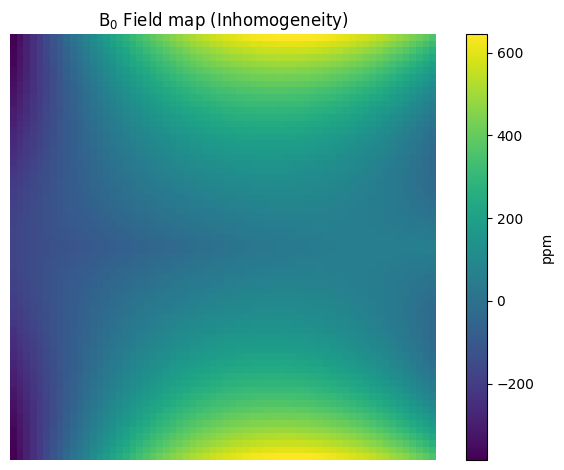

In [3]:
import matplotlib.pyplot as plt

plt.imshow(b0_map.squeeze())
plt.colorbar(label='ppm')
plt.title('B$_0$ Field map (Inhomogeneity)')
plt.axis('off')
plt.tight_layout()
plt.show()

## Simulate distorted k-space data
We simulate distorted k-space data by applying the B$_0$-informed Fourier operator to the phantom.

In [4]:

ro_bandwidth = 20e3
t_ro = torch.arange(matrix.x) / ro_bandwidth

fourier_op = mrpro.operators.FastFourierOp(dim=(-1, -2))
b0_fourier_op = mrpro.operators.ConjugatePhaseFourierOp(fourier_op=fourier_op, b0_map=b0_map, readout_times=t_ro)
(distorted_k,) = b0_fourier_op(img)

A simple inverse Fourier transform of the distorted k-space data gives us the distorted image.

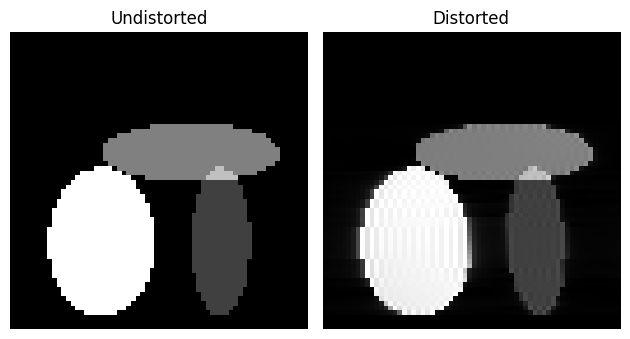

In [5]:
(distorted_img,) = fourier_op.H(distorted_k)


vmin, vmax = img.abs().aminmax()
fig, ax = plt.subplots(1, 2)
ax[0].imshow(img.abs().squeeze(), cmap='gray', vmin=vmin, vmax=vmax)
ax[0].set_title('Undistorted')
ax[1].imshow(distorted_img.abs().squeeze(), cmap='gray', vmin=vmin, vmax=vmax)
ax[1].set_title('Distorted')
ax[0].axis('off')
ax[1].axis('off')
plt.tight_layout()

## Correct for B0 inhomogeneity
We can use a faster approximation of the B0-informed Fourier operator, namely the Time-Segmented operator.
The adjoint already fixes geometric distortions, using conjugate gradient (CG) we can actually invert the operator and
also fix intensity inhomogeneities. This is necessry, as F^H F != I for B0-informed Fourier operators!

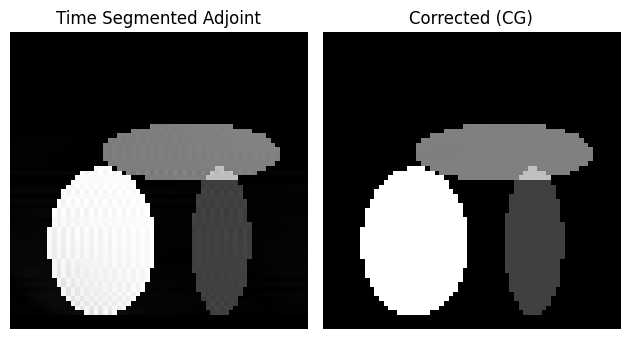

In [6]:


ts_fourier_op = mrpro.operators.TimeSegmentedFourierOp(fourier_op=fourier_op, b0_map=b0_map, readout_times=t_ro)

(b0_informed_img,) = ts_fourier_op.H(distorted_k)
(corrected_img,) = mrpro.algorithms.optimizers.cg(ts_fourier_op.gram, b0_informed_img)


fig, ax = plt.subplots(1, 2)
ax[0].imshow(b0_informed_img.abs().squeeze(), cmap='gray', vmin=vmin, vmax=vmax)
ax[0].set_title('Time Segmented Adjoint')
ax[1].imshow(corrected_img.abs().squeeze(), cmap='gray', vmin=vmin, vmax=vmax)
ax[1].set_title('Corrected (CG)')
ax[0].axis('off')
ax[1].axis('off')
plt.tight_layout()

## Summary
We have explored how to use the B0-informed Fourier operators to generate distorted k-space data and
and how to correct for B0 inhomogeneity in the reconstruction.